In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('../../src/zero_to_hero/part_02_makemore/names.txt', 'r').read().splitlines()

In [3]:
len(words)

32033

In [4]:
# We had S/E special tokens, but now just "."
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [5]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words[:5]:
  
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

In [6]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

In [7]:
# Building C - we'll try 2D (paper does 17000 words -> 30, we have 27 chars)

In [8]:
C = torch.randn((27, 2))

In [9]:
# How does e.g. 'e' encode?
print(C[5])

tensor([-1.0497,  0.8542])


In [10]:
# to see as before, one-hot - need to equalise dtype and have tensor input. More annoying
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([-1.0497,  0.8542])

In [11]:
# The C part is like a layer with identity activation, and weight matrix C

In [12]:
# Index with tensors in pytorch
C[X].shape

torch.Size([32, 3, 2])

In [13]:
# e.g.
print(X[13,2])
print(C[X][13,2])
print(C[1])

tensor(1)
tensor([0.2880, 0.7129])
tensor([0.2880, 0.7129])


In [14]:
# Hidden Layer - what size is it?
# Well we have our inputs embedded into 2 dimensional space (letter)
# And there are 3 letters in context - so 6
# n_hidden up to us
n_hidden = 100
W1 = torch.randn(6, n_hidden)
b1 = torch.randn(n_hidden)

In [15]:
# Note that C[X] @ W1 doesn't work immediately, we need to concatenate
print(C[X[0]])
emb = C[X]
torch.cat([emb[:,0], emb[:,1], emb[:,2]], dim=1).shape

tensor([[-0.0343,  0.0301],
        [-0.0343,  0.0301],
        [-0.0343,  0.0301]])


torch.Size([32, 6])

In [16]:
# Note trailing : isn't needed
emb_cat = torch.cat([emb[:,0], emb[:,1], emb[:,2]], dim=1)
op_1 = emb_cat @ W1 + b1

In [17]:
# Can do this neater and more general!
emb_cat = torch.cat(torch.unbind(emb, 1), dim=1)
op_1 = emb_cat @ W1 + b1

In [18]:
# Even better!
a = torch.arange(10)
print(a)
print(a.shape)

tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
torch.Size([10])


In [19]:
# Here's something... Need product of dimensions to be n_elements
# This is the most efficient. This definitely works below... why?
# More efficient as cat creates new memory, this is the same tensor
a.view(2,5)

tensor([[0, 1, 2, 3, 4],
        [5, 6, 7, 8, 9]])

In [20]:
# Internals, we have 1d vector of elements
# Difference with storaage, untyped_storage...?
a.storage()

/var/folders/k9/vl4kp0fn6dq2943v99cykxgw0000gn/T/ipykernel_88242/774139331.py:3: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  a.storage()


 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 10]

In [21]:
h1 = torch.tanh(emb.view(emb.shape[0],emb.shape[1] * emb.shape[2]) @ W1 + b1)

In [22]:
# Verify the adding has correct broadcasting as we like!

In [23]:
# Output layer
n_classes = 27
W2 = torch.randn((n_hidden, n_classes))
b2 = torch.randn(n_classes)

In [24]:
logits = h1 @ W2 + b2
logits.shape
counts = logits.exp()

In [25]:
# keepdims!!
prob = counts / counts.sum(axis=1, keepdims=True)

In [26]:
prob.sum(axis=1)

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000])

In [27]:
# Final probabilities
prob[torch.arange(32), Y]

tensor([1.1839e-06, 4.5775e-07, 2.8717e-07, 9.9997e-01, 1.4597e-01, 1.8546e-05,
        1.4810e-03, 1.0083e-08, 1.1852e-07, 8.6128e-09, 9.9953e-01, 2.5562e-03,
        2.2914e-03, 6.3357e-13, 2.2797e-09, 2.5857e-02, 2.2725e-03, 5.3425e-10,
        1.7226e-08, 6.2052e-09, 5.0222e-12, 3.8563e-12, 1.0413e-05, 5.9775e-09,
        5.5985e-08, 9.1973e-06, 3.3375e-13, 5.3703e-04, 1.5045e-09, 3.0982e-10,
        1.3159e-08, 5.7938e-04])

In [28]:
# Get NLL
loss = -prob[torch.arange(32), Y].log().mean()
print(loss)

tensor(14.3294)


In [29]:
# Why is this better? Efficiency, numerical stability
F.cross_entropy(logits, Y)

tensor(14.3295)

In [30]:
# ------------ tidying... ---------------

In [31]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [32]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [33]:
sum(p.nelement() for p in parameters) # number of parameters in total

3481

In [34]:
for p in parameters:
  p.requires_grad = True

In [35]:
lri = []
lossi = []
stepi = []

In [36]:
for p in parameters:
    p.requires_grad = True

In [37]:
emb.shape

torch.Size([32, 3, 2])

In [38]:
# Obviously looks great when we had 32 examples, 3400 parameters!
for _ in range(100):
    # forward pass
    emb = C[Xtr]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits,Ytr)
    print(loss.item())
    # Backward pass - should be none!
    for p in parameters:
        p.grad = None
    
    loss.backward()
    for p in parameters:
        p.data += -0.1 * p.grad

19.511638641357422
17.090280532836914
15.782454490661621
14.839418411254883
14.008926391601562
13.259845733642578
12.586752891540527
11.990052223205566
11.477109909057617
11.057565689086914
10.714484214782715
10.412144660949707
10.132030487060547
9.868267059326172
9.61803150177002
9.379547119140625
9.151601791381836
8.933303833007812
8.723962783813477
8.523032188415527
8.330081939697266
8.14477825164795
7.966869354248047
7.79618501663208
7.63260555267334
7.476044654846191
7.326401233673096
7.183539390563965
7.047248363494873
6.917240142822266
6.7931623458862305
6.674629211425781
6.561246871948242
6.45263671875
6.34844970703125
6.248366832733154
6.152106285095215
6.059411525726318
5.970061779022217
5.883861064910889
5.80063533782959
5.7202253341674805
5.642488479614258
5.567291259765625
5.494509696960449
5.424025535583496
5.3557281494140625
5.289514064788818
5.225286960601807
5.162955284118652
5.102437496185303
5.043659687042236
4.9865546226501465
4.931059837341309
4.877122402191162
4.8

In [39]:
# Note we can't have loss 0 - there are multiple examples of "..." -> something different, so impossible
# In other examples, can overfit perfectly

In [40]:
# Individual iterations take smaller
# In practice - people use minibatches - only updating using some small dataset (basically bagging?)

In [41]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [42]:

# minibatch construction
# This means gradient is noisy, but unbiased

mb_size = 100
for _ in range(1000):
    #minibatch
    ix = torch.randint(0, Xtr.shape[0], (mb_size,))
    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits,Ytr[ix])
    print(loss.item())
    # Backward pass - should be none!
    for p in parameters:
        p.grad = None
    
    loss.backward()
    for p in parameters:
        p.data += -0.1 * p.grad

18.582534790039062
15.822671890258789
16.332883834838867
15.560242652893066
14.094926834106445
12.347517013549805
12.554495811462402
11.996712684631348
11.423273086547852
12.96004867553711
10.427892684936523
9.525300025939941
9.795040130615234
9.720203399658203
9.190179824829102
10.13387393951416
10.250123023986816
7.5514116287231445
8.373867988586426
8.776101112365723
7.313324451446533
7.7360758781433105
7.6480326652526855
7.412992477416992
8.368110656738281
8.799129486083984
7.277891635894775
8.568913459777832
5.848251819610596
6.93787956237793
7.25374698638916
7.36624002456665
7.105856418609619
6.88604736328125
6.244924545288086
6.765411853790283
6.473902702331543
6.967958927154541
6.021078109741211
6.133730411529541
6.1464385986328125
6.10984992980957
6.3426432609558105
5.097505569458008
4.557094097137451
5.557605743408203
6.8011794090271
5.3105549812316895
5.7638702392578125
5.206137657165527
4.72553014755249
6.295841217041016
4.994843006134033
5.255725860595703
4.485515117645264


In [43]:
    emb = C[Xtr]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits,Ytr)
    print(loss)

tensor(2.5916, grad_fn=<NllLossBackward0>)


In [44]:
# Can just use X.tensor_split for Xtr,Xte

In [45]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [46]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
lri = []
lossi = []
stepi = []

In [47]:
# Learning rate search: step i uses lr = 10**lre[i], sweeping 0.001 -> 1 over 1000 steps
mb_size = 100
for i in range(1000):
    #minibatch
    ix = torch.randint(0, Xtr.shape[0], (mb_size,))
    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits,Ytr[ix])
    # Backward pass - should be none!
    for p in parameters:
        p.grad = None

    loss.backward()
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    # track the exponent, so the plot's x axis is log10(lr)
    lri.append(lre[i])
    lossi.append(loss.item())
print(loss.item())

5.540630340576172


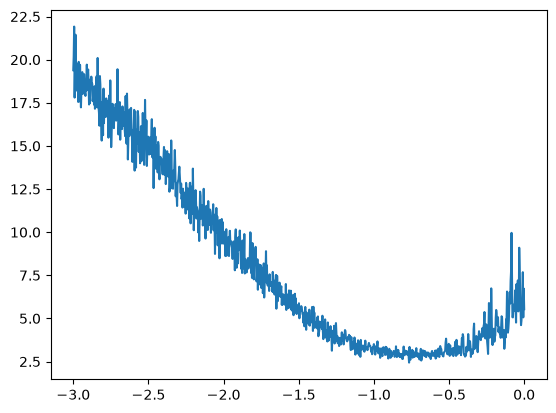

In [48]:
# Pick something in the valley - 0.1 good
plt.plot(lri,lossi)

In [49]:
# At late stages we can decay learning rate - here he just did some loops at 0.1, then some at 0.01

In [50]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [51]:
mb_size = 100
for i in range(30000):
    #full batch
    ix = torch.randint(0, Xtr.shape[0], (mb_size,))
    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits,Ytr[ix])
    #print(loss.item())
    # Backward pass - should be none!
    for p in parameters:
        p.grad = None
    
    loss.backward()
    lr = 0.1
    for p in parameters:
        p.data += -lr * p.grad

    #lri.append(lrs[i])
    #lossi.append(loss.item())
print(loss.item())

2.2840120792388916


In [52]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.3591, grad_fn=<NllLossBackward0>)

In [53]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.3608, grad_fn=<NllLossBackward0>)

In [54]:
# train/test loss roughly equal - not overfitting, probably underfitting
# Try scaling the network -we also tried other bottlenecks (changing embedding dimension)

In [55]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
n_hidden = 300
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [56]:
sum(p.nelement() for p in parameters) # number of parameters in total

10281

In [57]:
lri = []
lossi = []
stepi = []

# I did two loops with 0.1, one with 0.1/2 - originally by rerunning the cell, now one loop per lr
mb_size = 100
schedule = [(0.1, 10000), (0.1, 10000), (0.1 / 2, 10000)] # (lr, steps)
step = 0
for lr, n_steps in schedule:
    for _ in range(n_steps):
        #minibatch
        ix = torch.randint(0, Xtr.shape[0], (mb_size,))
        # forward pass
        emb = C[Xtr[ix]]
        h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
        logits = h @ W2 + b2
        loss = F.cross_entropy(logits,Ytr[ix])
        # Backward pass - should be none!
        for p in parameters:
            p.grad = None

        loss.backward()
        for p in parameters:
            p.data += -lr * p.grad

        lri.append(lr)
        lossi.append(loss.item())
        stepi.append(step)
        step += 1
    print(f"lr {lr}: {n_steps} steps, last minibatch loss {loss.item():.4f}")

lr 0.1: 10000 steps, last minibatch loss 2.4087
lr 0.1: 10000 steps, last minibatch loss 2.5965
lr 0.05: 10000 steps, last minibatch loss 2.5053


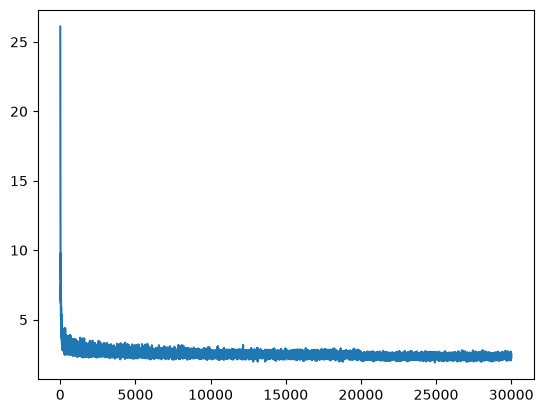

In [58]:
plt.plot(stepi, lossi)

In [59]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.3346, grad_fn=<NllLossBackward0>)

In [60]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.3349, grad_fn=<NllLossBackward0>)

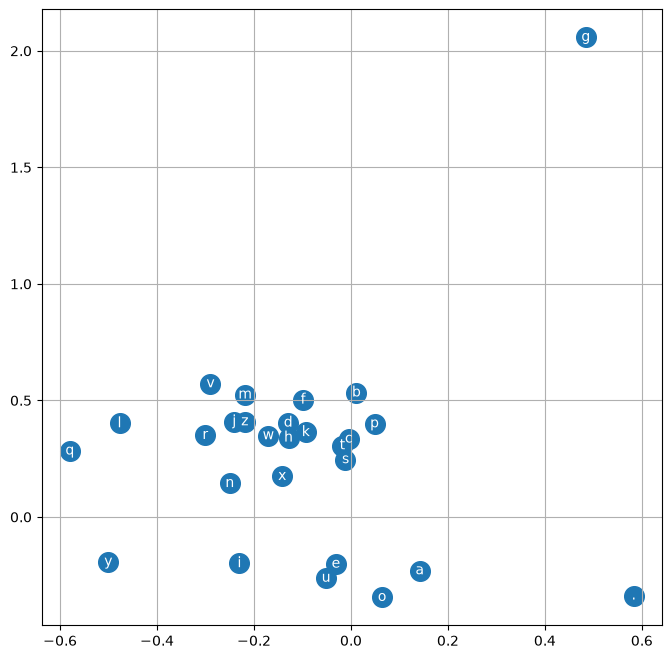

In [61]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters - this was with 2D embeddings
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [62]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
n_hidden = 200
n_embedding = 10
n_context = 3
C = torch.randn((27, n_embedding), generator=g)
W1 = torch.randn((n_context * n_embedding, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [63]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [64]:
lri = []
lossi = []
stepi = []

In [65]:
# one with lr 0.1, one with lr 0.01 - originally by rerunning the cell, now one loop per lr
mb_size = 32
schedule = [(0.1, 50000), (0.1 / 10, 50000)] # (lr, steps)
step = 0
for lr, n_steps in schedule:
    for _ in range(n_steps):
        #minibatch
        ix = torch.randint(0, Xtr.shape[0], (mb_size,))
        # forward pass
        emb = C[Xtr[ix]]
        h = torch.tanh(emb.view(-1, n_embedding * n_context) @ W1 + b1)
        logits = h @ W2 + b2
        loss = F.cross_entropy(logits,Ytr[ix])
        # Backward pass - should be none!
        for p in parameters:
            p.grad = None

        loss.backward()
        for p in parameters:
            p.data += -lr * p.grad

        lri.append(lr)
        lossi.append(loss.log10().item())
        stepi.append(step)
        step += 1
    print(f"lr {lr}: {n_steps} steps, last minibatch loss {loss.item():.4f}")

lr 0.1: 50000 steps, last minibatch loss 2.2693
lr 0.01: 50000 steps, last minibatch loss 2.5805


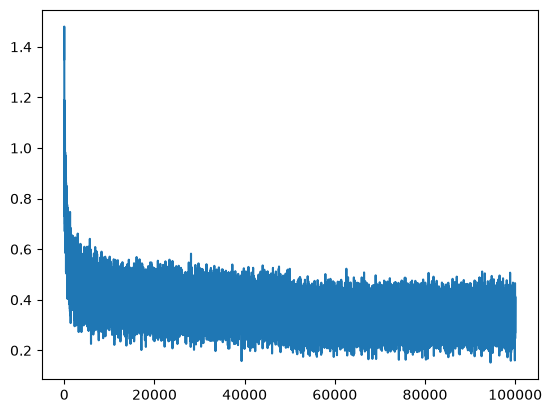

In [66]:
plt.plot(stepi, lossi)

In [67]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, n_embedding * n_context) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1779, grad_fn=<NllLossBackward0>)

In [68]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, n_embedding * n_context) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2122, grad_fn=<NllLossBackward0>)

In [69]:
# Can tune hyperparameters (context, embedding)...
# Use better optimisation?
# He uses 100,000 0.1 and 0.01 - gets 2.16 on dev, 2.12 on train
# Hyperparameters to tune - (C-dimension, context size, number of neurons, proper learning rate?, batch size)
# Read paper and do things

In [70]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carmah.
amelle.
khi.
mre.
reh.
cassandene.
mahuen.
amerric.
kaeli.
nellara.
chaiivay.
legy.
halm.
joli.
quintzonovera.
jadii.
wazelo.
dearyni.
jaceelinsabeed.
ediia.
